In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:

df = pd.read_csv('/content/dataset.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (35717, 4)


,SystemCodeNumber,Capacity,Occupancy,LastUpdated
0,BHMBCCMKT01,577,61,2016-10-04 07:59:42
1,BHMBCCMKT01,577,64,2016-10-04 08:25:42
2,BHMBCCMKT01,577,80,2016-10-04 08:59:42
3,BHMBCCMKT01,577,107,2016-10-04 09:32:46
4,BHMBCCMKT01,577,150,2016-10-04 09:59:48


In [ ]:

# Step 5: Explore the parking dataset

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nFirst 10 records:")
display(df.head(10))

print("\nStatistical summary:")
display(df.describe())


Dataset shape: (35717, 4)

Column names:
['SystemCodeNumber', 'Capacity', 'Occupancy', 'LastUpdated']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35717 entries, 0 to 35716
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   SystemCodeNumber  35717 non-null  object
 1   Capacity          35717 non-null  int64 
 2   Occupancy         35717 non-null  int64 
 3   LastUpdated       35717 non-null  object
dtypes: int64(2), object(2)
memory usage: 1.1+ MB

Missing values in each column:
SystemCodeNumber    0
Capacity            0
Occupancy           0
LastUpdated         0
dtype: int64

First 10 records:


,SystemCodeNumber,Capacity,Occupancy,LastUpdated
0,BHMBCCMKT01,577,61,2016-10-04 07:59:42
1,BHMBCCMKT01,577,64,2016-10-04 08:25:42
2,BHMBCCMKT01,577,80,2016-10-04 08:59:42
3,BHMBCCMKT01,577,107,2016-10-04 09:32:46
4,BHMBCCMKT01,577,150,2016-10-04 09:59:48
5,BHMBCCMKT01,577,177,2016-10-04 10:26:49
6,BHMBCCMKT01,577,219,2016-10-04 10:59:48
7,BHMBCCMKT01,577,247,2016-10-04 11:25:47
8,BHMBCCMKT01,577,259,2016-10-04 11:59:44
9,BHMBCCMKT01,577,266,2016-10-04 12:29:45



Statistical summary:


,Capacity,Occupancy
count,35717.000000,35717.000000
mean,1397.550130,642.228911
std,1179.326833,656.955535
min,220.000000,-8.000000
25%,500.000000,210.000000
50%,849.000000,446.000000
75%,2009.000000,798.000000
max,4675.000000,4327.000000


In [ ]:

# Step 6: Clean the data

df.columns = df.columns.str.strip()

# Convert timestamp into datetime format
df['LastUpdated'] = pd.to_datetime(
    df['LastUpdated'], errors='coerce'
)

# Remove records with missing essential values
df = df.dropna(
    subset=['SystemCodeNumber', 'Capacity',
            'Occupancy', 'LastUpdated']
)

# Remove invalid parking records
df = df[
    (df['Capacity'] > 0) &
    (df['Occupancy'] >= 0) &
    (df['Occupancy'] <= df['Capacity'])
].copy()

# Create useful features from the timestamp
df['Hour'] = df['LastUpdated'].dt.hour
df['DayOfWeek'] = df['LastUpdated'].dt.dayofweek
df['Month'] = df['LastUpdated'].dt.month
df['IsWeekend'] = (
    df['DayOfWeek'] >= 5
).astype(int)

# Calculate occupancy percentage
df['OccupancyPercentage'] = (
    df['Occupancy'] / df['Capacity']
) * 100

print("Data cleaning completed!")
print("Cleaned dataset shape:", df.shape)

display(df.head())


Data cleaning completed!
Cleaned dataset shape: (35332, 9)


,SystemCodeNumber,Capacity,Occupancy,LastUpdated,Hour,DayOfWeek,Month,IsWeekend,OccupancyPercentage
0,BHMBCCMKT01,577,61,2016-10-04 07:59:42,7,1,10,0,10.571924
1,BHMBCCMKT01,577,64,2016-10-04 08:25:42,8,1,10,0,11.091854
2,BHMBCCMKT01,577,80,2016-10-04 08:59:42,8,1,10,0,13.864818
3,BHMBCCMKT01,577,107,2016-10-04 09:32:46,9,1,10,0,18.544194
4,BHMBCCMKT01,577,150,2016-10-04 09:59:48,9,1,10,0,25.996534


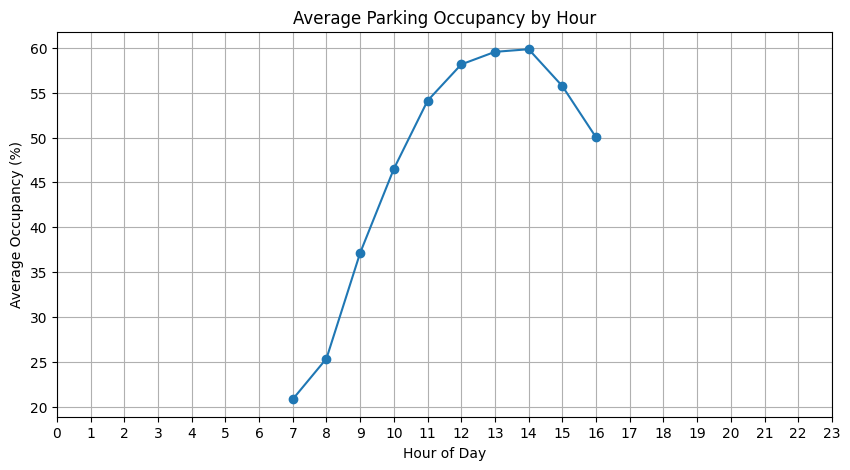

In [ ]:

import matplotlib.pyplot as plt

# Average occupancy by hour
hourly_occupancy = df.groupby('Hour')[
    'OccupancyPercentage'
].mean()

plt.figure(figsize=(10, 5))
hourly_occupancy.plot(marker='o')
plt.title('Average Parking Occupancy by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Average Occupancy (%)')
plt.xticks(range(24))
plt.grid(True)
plt.show()


In [ ]:
display(df)

,SystemCodeNumber,Capacity,Occupancy,LastUpdated,Hour,DayOfWeek,Month,IsWeekend,OccupancyPercentage
0,BHMBCCMKT01,577,61,2016-10-04 07:59:42,7,1,10,0,10.571924
1,BHMBCCMKT01,577,64,2016-10-04 08:25:42,8,1,10,0,11.091854
2,BHMBCCMKT01,577,80,2016-10-04 08:59:42,8,1,10,0,13.864818
3,BHMBCCMKT01,577,107,2016-10-04 09:32:46,9,1,10,0,18.544194
4,BHMBCCMKT01,577,150,2016-10-04 09:59:48,9,1,10,0,25.996534
...,...,...,...,...,...,...,...,...,...
35712,Shopping,1920,1517,2016-12-19 14:30:33,14,0,12,0,79.010417
35713,Shopping,1920,1487,2016-12-19 15:03:34,15,0,12,0,77.447917
35714,Shopping,1920,1432,2016-12-19 15:29:33,15,0,12,0,74.583333
35715,Shopping,1920,1321,2016-12-19 16:03:35,16,0,12,0,68.802083


In [ ]:

# Step 8: Select features and target

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

# Input features
X = df[
    ['SystemCodeNumber', 'Capacity',
     'Hour', 'DayOfWeek', 'Month', 'IsWeekend']
]

# Target variable
y = df['Occupancy']

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Features and target prepared!")



Features shape: (35332, 6)
Target shape: (35332,)
Features and target prepared!


In [ ]:

# Sort chronologically
df = df.sort_values('LastUpdated').reset_index(drop=True)

X = df[
    ['SystemCodeNumber', 'Capacity',
     'Hour', 'DayOfWeek', 'Month', 'IsWeekend']
]
y = df['Occupancy']

split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 28265
Testing records: 7067


In [ ]:

# Identify numerical and categorical columns

categorical_features = ['SystemCodeNumber']
numerical_features = [
    'Capacity', 'Hour', 'DayOfWeek',
    'Month', 'IsWeekend'
]

preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'),
     numerical_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'),
     categorical_features)
])

# Model 1: Linear Regression
linear_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

linear_model.fit(X_train, y_train)
linear_predictions = linear_model.predict(X_test)

# Model 2: Decision Tree
tree_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeRegressor(
        max_depth=10, random_state=42
    ))
])

tree_model.fit(X_train, y_train)
tree_predictions = tree_model.predict(X_test)
print("Both models trained successfully!")


Both models trained successfully!


In [ ]:

import numpy as np
import pandas as pd

def evaluate_model(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    return {
        'Model': name,
        'MAE': round(mae, 2),
        'RMSE': round(rmse, 2),
        'R2 Score': round(r2, 4)
    }

results = pd.DataFrame([
    evaluate_model(
        'Linear Regression', y_test, linear_predictions
    ),
    evaluate_model(
        'Decision Tree', y_test, tree_predictions
    )
])

display(results)


,Model,MAE,RMSE,R2 Score
0,Linear Regression,207.83,338.13,0.7854
1,Decision Tree,98.04,168.71,0.9466


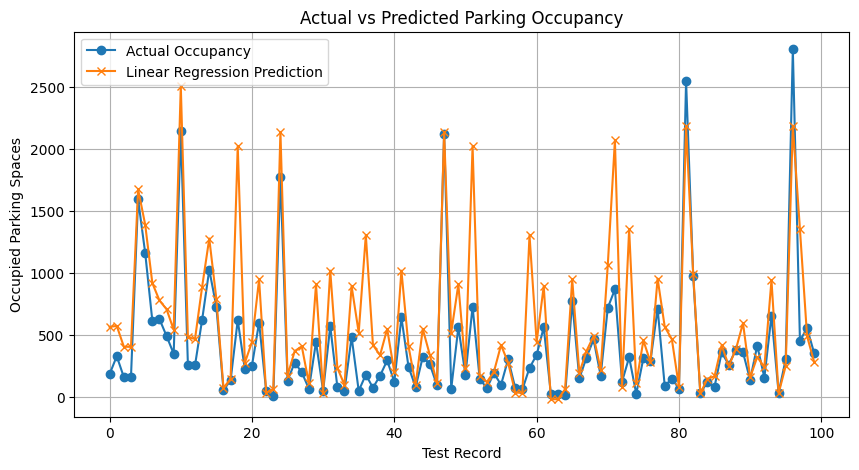

In [ ]:

plt.figure(figsize=(10, 5))

plt.plot(
    list(y_test.iloc[:100]),
    label='Actual Occupancy',
    marker='o'
)

plt.plot(
    linear_predictions[:100],
    label='Linear Regression Prediction',
    marker='x'
)

plt.title('Actual vs Predicted Parking Occupancy')
plt.xlabel('Test Record')
plt.ylabel('Occupied Parking Spaces')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
display(results.sort_values(by="MAE"))

best_model_name = results.sort_values(
    by="MAE"
).iloc[0]["Model"]

print("Best model based on MAE:", best_model_name)

,Model,MAE,RMSE,R2 Score
1,Decision Tree,98.04,168.71,0.9466
0,Linear Regression,207.83,338.13,0.7854


Best model based on MAE: Decision Tree


In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

location_dropdown = widgets.Dropdown(
    options=sorted(df["SystemCodeNumber"].unique()),
    description="Parking:"
)

hour_slider = widgets.IntSlider(
    value=10, min=0, max=23,
    description="Hour:"
)

day_dropdown = widgets.Dropdown(
    options=[
        ("Monday", 0), ("Tuesday", 1),
        ("Wednesday", 2), ("Thursday", 3),
        ("Friday", 4), ("Saturday", 5),
        ("Sunday", 6)
    ],
    description="Day:"
)

predict_button = widgets.Button(
    description="Predict Parking",
    button_style="success"
)

output = widgets.Output()

def predict_parking(b):
    with output:
        clear_output()

        location = location_dropdown.value
        hour = hour_slider.value
        day = day_dropdown.value

        capacity = int(
            df.loc[
                df["SystemCodeNumber"] == location,
                "Capacity"
            ].median()
        )

        month = int(df["Month"].median())
        weekend = int(day >= 5)

        sample = pd.DataFrame([{
            "SystemCodeNumber": location,
            "Capacity": capacity,
            "Hour": hour,
            "DayOfWeek": day,
            "Month": month,
            "IsWeekend": weekend
        }])

        model = (
            linear_model if best_model_name == "Linear Regression"
            else tree_model
        )

        predicted = float(model.predict(sample)[0])
        predicted = max(0, min(capacity, round(predicted)))
        available = capacity - predicted

        print("Parking location:", location)
        print("Parking capacity:", capacity)
        print("Predicted occupied spaces:", predicted)
        print("Predicted available spaces:", available)
        print("Predicted occupancy:", round(predicted / capacity * 100, 2), "%")

predict_button.on_click(predict_parking)

display(
    location_dropdown,
    hour_slider,
    day_dropdown,
    predict_button,
    output
)

Dropdown(description='Parking:', options=('BHMBCCMKT01', 'BHMBCCPST01', 'BHMBCCSNH01', 'BHMBCCTHL01', 'BHMBRCB…

IntSlider(value=10, description='Hour:', max=23)

Dropdown(description='Day:', options=(('Monday', 0), ('Tuesday', 1), ('Wednesday', 2), ('Thursday', 3), ('Frid…

Button(button_style='success', description='Predict Parking', style=ButtonStyle())

Output()

In [ ]:

# Restore the processed dataset from your existing dataframe

if "processed_df" not in globals():
    if "df" in globals():
        processed_df = df.copy()
        print("Created processed_df from df")
    else:
        raise NameError(
            "Neither processed_df nor df exists. "
            "Please reload your CSV dataset."
        )

print("Dataset shape:", processed_df.shape)
print("Columns:", processed_df.columns.tolist())
display(processed_df.head())


Created processed_df from df
Dataset shape: (35332, 9)
Columns: ['SystemCodeNumber', 'Capacity', 'Occupancy', 'LastUpdated', 'Hour', 'DayOfWeek', 'Month', 'IsWeekend', 'OccupancyPercentage']


,SystemCodeNumber,Capacity,Occupancy,LastUpdated,Hour,DayOfWeek,Month,IsWeekend,OccupancyPercentage
0,BHMNCPPLS01,450,76,2016-10-04 07:46:28,7,1,10,0,16.888889
1,BHMNCPPLS01,450,76,2016-10-04 07:46:28,7,1,10,0,16.888889
2,BHMBCCMKT01,577,61,2016-10-04 07:59:42,7,1,10,0,10.571924
3,BHMBRCBRG01,1010,70,2016-10-04 07:59:42,7,1,10,0,6.930693
4,NIA Car Parks,1268,74,2016-10-04 07:59:42,7,1,10,0,5.835962


In [ ]:

required_columns = [
    "SystemCodeNumber",
    "Capacity",
    "Occupancy",
    "LastUpdated"
]

missing = [
    col for col in required_columns
    if col not in processed_df.columns
]

if missing:
    print("Missing columns:", missing)
    print("Available columns:", processed_df.columns.tolist())
else:
    print("All required columns are available!")


All required columns are available!


In [ ]:

# STEP 1: Prepare time-based features

import pandas as pd
import numpy as np

# Work on a separate copy
time_data = processed_df.copy()

# Ensure the date column has the correct format
time_data["LastUpdated"] = pd.to_datetime(
    time_data["LastUpdated"], errors="coerce"
)

# Remove invalid rows and sort readings by parking location and time
time_data = time_data.dropna(
    subset=["SystemCodeNumber", "Capacity", "Occupancy", "LastUpdated"]
)

time_data = time_data.sort_values(
    ["SystemCodeNumber", "LastUpdated"]
).reset_index(drop=True)

# Create time features if they do not already exist
time_data["Hour"] = time_data["LastUpdated"].dt.hour
time_data["DayOfWeek"] = time_data["LastUpdated"].dt.dayofweek
time_data["Month"] = time_data["LastUpdated"].dt.month
time_data["IsWeekend"] = (time_data["DayOfWeek"] >= 5).astype(int)

# Use only previous readings for each parking location
grouped = time_data.groupby("SystemCodeNumber")["Occupancy"]

time_data["Lag_1"] = grouped.shift(1)
time_data["Lag_2"] = grouped.shift(2)

time_data["Rolling_Mean_3"] = grouped.transform(
    lambda s: s.shift(1).rolling(window=3, min_periods=3).mean()
)

time_data["Occupancy_Change"] = (
    time_data["Lag_1"] - time_data["Lag_2"]
)

# Remove rows that don't yet have enough historical readings
time_data = time_data.dropna(
    subset=["Lag_1", "Lag_2", "Rolling_Mean_3", "Occupancy_Change"]
).reset_index(drop=True)

print("Original processed dataset:", processed_df.shape)
print("Time-aware dataset:", time_data.shape)
print("\nNew features created:")
print(["Lag_1", "Lag_2", "Rolling_Mean_3", "Occupancy_Change"])

display(time_data.head())


Original processed dataset: (35332, 9)
Time-aware dataset: (35242, 13)

New features created:
['Lag_1', 'Lag_2', 'Rolling_Mean_3', 'Occupancy_Change']


,SystemCodeNumber,Capacity,Occupancy,LastUpdated,Hour,DayOfWeek,Month,IsWeekend,OccupancyPercentage,Lag_1,Lag_2,Rolling_Mean_3,Occupancy_Change
0,BHMBCCMKT01,577,107,2016-10-04 09:32:46,9,1,10,0,18.544194,80.0,64.0,68.333333,16.0
1,BHMBCCMKT01,577,150,2016-10-04 09:59:48,9,1,10,0,25.996534,107.0,80.0,83.666667,27.0
2,BHMBCCMKT01,577,177,2016-10-04 10:26:49,10,1,10,0,30.675910,150.0,107.0,112.333333,43.0
3,BHMBCCMKT01,577,219,2016-10-04 10:59:48,10,1,10,0,37.954939,177.0,150.0,144.666667,27.0
4,BHMBCCMKT01,577,247,2016-10-04 11:25:47,11,1,10,0,42.807626,219.0,177.0,182.000000,42.0


In [ ]:

# STEP 2: Train and evaluate the time-aware Random Forest

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Features available to the model
numeric_features = [
    "Capacity", "Hour", "DayOfWeek", "Month", "IsWeekend",
    "Lag_1", "Lag_2", "Rolling_Mean_3", "Occupancy_Change"
]
categorical_features = ["SystemCodeNumber"]
all_features = numeric_features + categorical_features
target = "Occupancy"

# Sort chronologically before splitting
time_data = time_data.sort_values("LastUpdated").reset_index(drop=True)

# 80% earlier observations for training, 20% later observations for testing
split_index = int(len(time_data) * 0.8)

train_data = time_data.iloc[:split_index].copy()
test_data = time_data.iloc[split_index:].copy()

X_train_time = train_data[all_features]
y_train_time = train_data[target]

X_test_time = test_data[all_features]
y_test_time = test_data[target]

# Preprocess numeric and categorical features
preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric_features),
    ("location", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

# Build the model pipeline
time_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=150,
        max_depth=12,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

# Train
time_model.fit(X_train_time, y_train_time)

# Predict the later observations
time_predictions = time_model.predict(X_test_time)

# Evaluate
mae = mean_absolute_error(y_test_time, time_predictions)
rmse = np.sqrt(mean_squared_error(y_test_time, time_predictions))
r2 = r2_score(y_test_time, time_predictions)

print("TIME-AWARE RANDOM FOREST RESULTS")
print("--------------------------------")
print("Training rows:", len(train_data))
print("Testing rows:", len(test_data))
print(f"MAE:  {mae:.2f} spaces")
print(f"RMSE: {rmse:.2f} spaces")
print(f"R²:   {r2:.4f}")

# Keep predictions within each location's capacity for display
results = test_data[
    ["LastUpdated", "SystemCodeNumber", "Capacity", "Occupancy"]
].copy()

results["Predicted_Occupancy"] = np.clip(
    time_predictions, 0, results["Capacity"].to_numpy()
)
results["Estimated_Free_Spaces"] = (
    results["Capacity"] - results["Predicted_Occupancy"]
)

display(results.head(10))


TIME-AWARE RANDOM FOREST RESULTS
--------------------------------
Training rows: 28193
Testing rows: 7049
MAE:  23.73 spaces
RMSE: 56.23 spaces
R²:   0.9941


,LastUpdated,SystemCodeNumber,Capacity,Occupancy,Predicted_Occupancy,Estimated_Free_Spaces
28193,2016-12-02 16:32:54,BHMNCPHST01,1200,520,549.429678,650.570322
28194,2016-12-05 07:56:03,BHMNCPNST01,485,136,173.465473,311.534527
28195,2016-12-05 07:56:03,BHMBRCBRG03,849,55,98.899967,750.100033
28196,2016-12-05 08:02:03,Bull Ring,3053,180,280.249177,2772.750823
28197,2016-12-05 08:02:03,Broad Street,690,172,203.857591,486.142409
28198,2016-12-05 08:02:03,BHMBCCPST01,317,49,87.864382,229.135618
28199,2016-12-05 08:02:03,BHMNCPNHS01,500,81,132.385583,367.614417
28200,2016-12-05 08:02:03,Others-CCCPS105a,2009,572,689.700124,1319.299876
28201,2016-12-05 08:02:03,BHMEURBRD02,220,49,95.432562,124.567438
28202,2016-12-05 08:02:03,BHMMBMMBX01,687,277,315.291386,371.708614
